# MEMBER4 - Normalization / Scaling

**Dataset:** Ames Housing (`train.csv`, 1,460 houses, 79 features + `SalePrice`)  
**Task:** predict the sale price of a house (regression).  
Run this notebook from the `notebooks/` folder so the `../data/raw/` paths resolve.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
%matplotlib inline

df = pd.read_csv('../data/raw/train.csv')
test = pd.read_csv('../data/raw/test.csv')
print('train:', df.shape, '| test:', test.shape)
df.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Scale differences between features

In [2]:
cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF', 'YearBuilt', 'OverallQual']
df[cols].describe().loc[['min', 'max', 'mean', 'std']].round(1)

,LotArea,GrLivArea,TotalBsmtSF,YearBuilt,OverallQual
min,1300.0,334.0,0.0,1872.0,1.0
max,215245.0,5642.0,6110.0,2010.0,10.0
mean,10516.8,1515.5,1057.4,1971.3,6.1
std,9981.3,525.5,438.7,30.2,1.4


## 2. Apply three scalers (fitted on the training split only)

StandardScaler -> mean 0, std 1. MinMaxScaler -> range [0, 1]. RobustScaler -> median 0, scaled by IQR (resistant to outliers).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

tr, ho = train_test_split(df, test_size=0.2, random_state=42)
scaled = {}
for name, sc in [('Standard', StandardScaler()), ('MinMax', MinMaxScaler()), ('Robust', RobustScaler())]:
    sc.fit(tr[cols])                                   # learn on train only -> no leakage
    scaled[name] = pd.DataFrame(sc.transform(ho[cols]), columns=cols)
for name, d in scaled.items():
   print(name, '-> hold-out min/max:',
      round(d.min().min(), 2), '/',
      round(d.max().max(), 2))
scaled['MinMax'].describe().loc[['min', 'max']].round(2)

Standard -> hold-out min/max: -3.01 / 5.59
MinMax -> hold-out min/max: 0.0 / 1.0
Robust -> hold-out min/max: -2.0 / 14.87


,LotArea,GrLivArea,TotalBsmtSF,YearBuilt,OverallQual
min,0.00,0.03,0.00,0.06,0.11
max,0.32,0.75,0.52,0.99,1.00


## 3. EDA visualizations

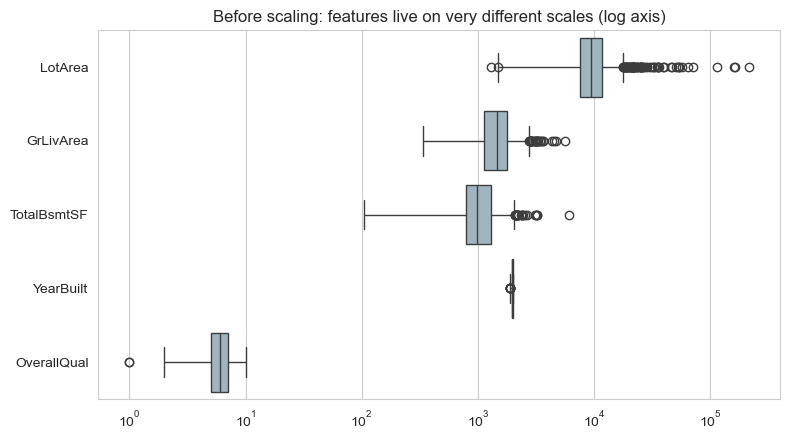

In [5]:
os.makedirs('../results/eda_visualizations/Scaling', exist_ok=True)
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df[cols], orient='h', color='#9CB7C5'); plt.xscale('log')
plt.title('Before scaling: features live on very different scales (log axis)')
plt.tight_layout(); plt.savefig('../results/eda_visualizations/Scaling/before_scaling.png', dpi=120); plt.show()

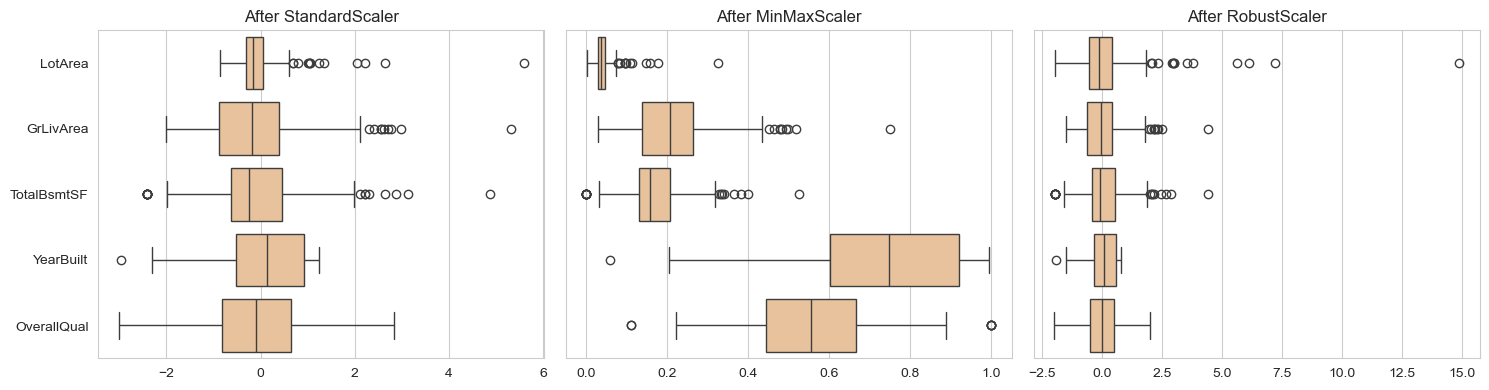

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, d) in zip(axes, scaled.items()):
    sns.boxplot(data=d, orient='h', ax=ax, color='#F4C28F'); ax.set_title(f'After {name}Scaler')
plt.tight_layout(); plt.savefig('../results/eda_visualizations/Scaling/after_scaling.png', dpi=120); plt.show()

## 4. Does scaling change model accuracy? (KNN on numeric features, 5-fold CV RMSLE)

No scaling    0.2217
MinMax        0.1903
Standard      0.1774
Robust        0.2485
dtype: float64


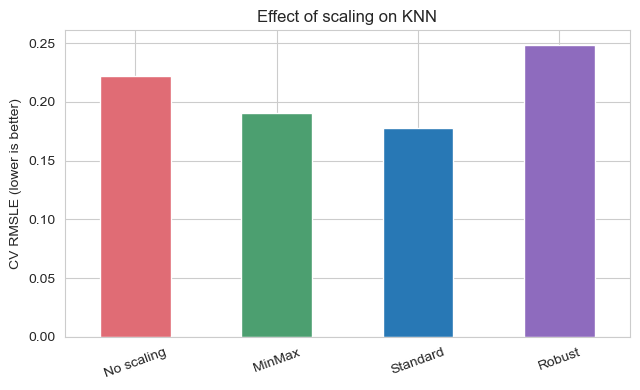

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score, KFold

X = df.drop(columns=['Id', 'SalePrice', 'MSSubClass']).select_dtypes(include='number')
y = np.log1p(df['SalePrice'])
cv = KFold(5, shuffle=True, random_state=42)
results = {}
for name, sc in [('No scaling', None), ('MinMax', MinMaxScaler()), ('Standard', StandardScaler()), ('Robust', RobustScaler())]:
    steps = [SimpleImputer(strategy='median')] + ([sc] if sc else []) + [KNeighborsRegressor(n_neighbors=8)]
    results[name] = -cross_val_score(make_pipeline(*steps), X, y, cv=cv, scoring='neg_root_mean_squared_error').mean()
res = pd.Series(results).round(4)
print(res)
plt.figure(figsize=(6.5, 4)); res.plot(kind='bar', color=['#E06C75', '#4C9F70', '#2878B5', '#8E6BBE'])
plt.ylabel('CV RMSLE (lower is better)'); plt.title('Effect of scaling on KNN'); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig('../results/eda_visualizations/Scaling/scaler_effect_knn.png', dpi=120); plt.show()

### Interpretation

`LotArea` is in the thousands while `OverallQual` is on a 1-10 scale, so unscaled distance-based models (KNN, SVR) are dominated by the large-valued columns. The last experiment shows the effect on KNN's cross-validated RMSLE: **StandardScaler is best (0.177)**, MinMax is next (0.190), no scaling is clearly worse (0.222), and **RobustScaler is the worst (0.249)**. Robust scaling divides by the IQR, which is 0 or tiny for sparse columns such as `PoolArea` or `3SsnPorch`, so rare non-zero values explode (hold-out maximum about 14.9 in the table above) and swamp the distance. Min-Max squeezes values into [0, 1] but is sensitive to extreme values (the huge lots). Scalers are always **fitted on the training split only** and then applied to the hold-out/test data to avoid leakage. The individual model notebooks tune StandardScaler vs MinMaxScaler as part of the grid search.